# Worlds 2026 Winner Predictor

Predicts each quarterfinalist's probability of winning the 2026 League of Legends World Championship using Oracle's Elixir match data (2024–2026), team- and player-level features, a game-outcome model, and Monte Carlo simulation of the knockout bracket.

See the [README](https://github.com/argyroselene/worlds2026-predictor#readme) for the method. Outputs shown are from the run on 2026-11-01 (data through 2026-10-22, after the Swiss stage).

## Setup

In [ ]:
import os, subprocess

REPO_URL = "https://github.com/argyroselene/worlds2026-predictor.git"
if os.path.exists("src/run.py"):
    pass                                   # already at the repo root
elif os.path.exists("../src/run.py"):
    os.chdir("..")                         # opened from notebooks/
else:
    if not os.path.exists("worlds2026-predictor"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "worlds2026-predictor"], check=True)
    os.chdir("worlds2026-predictor")
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
print("Working directory:", os.getcwd())

## Data

Download the yearly match-data CSVs from [Oracle's Elixir](https://oracleselixir.com/tools/downloads) (2024 onward). Set `SOURCE` to where they are:

| `SOURCE` | Location |
|---|---|
| `"files"` | Uploaded through Colab's Files panel (anywhere under `/content`) |
| `"drive"` | A Google Drive folder (`DRIVE_FOLDER`) |
| `"local"` | Already in `data/` |

In [37]:
import glob, shutil

SOURCE = "files"
DRIVE_FOLDER = "/content/drive/MyDrive/lol_data"

if SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    candidates = glob.glob(os.path.join(DRIVE_FOLDER, "*.csv"))
elif SOURCE == "files":
    candidates = [f for f in glob.glob("/content/**/*.csv", recursive=True)
                  if not any(x in f for x in ("/data/", "sample_data", "/outputs/", "/drive/"))]
else:
    candidates = []
for f in candidates:
    shutil.copy(f, "data/")

print("CSV files found:", sorted(f for f in os.listdir("data") if f.endswith(".csv")))

CSV files found: ['2024_LoL_esports_match_data_from_OraclesElixir.csv', '2025_LoL_esports_match_data_from_OraclesElixir.csv', '2026_LoL_esports_match_data_from_OraclesElixir.csv']


## Knockout results

Series already played are fixed in the simulation. One row per series, using the team names in `src/worlds2026.py`.

In [38]:
results = """
team_a,team_b,winner
"""

rows = [l.strip() for l in results.splitlines() if l.strip() and not l.strip().startswith("#")]
path = "data/knockout_results.csv"
if len(rows) > 1:
    with open(path, "w") as f:
        f.write("\n".join(rows) + "\n")
elif os.path.exists(path):
    os.remove(path)
print(f"{len(rows) - 1} knockout results fixed")

0 knockout results entered


## Parameters

| Parameter | Meaning |
|---|---|
| `SIMS` | Number of simulated tournaments |
| `UNCERTAINTY` | Std. dev. of the per-team random strength offset (log-odds) in each simulation |
| `HALF_LIFE` | Recency half-life for training weights, in days (`0` = equal weights) |
| `BIG_STAGE` | Scale of the Worlds track-record offset (`0` = off) |
| `THIS_WORLDS` | Scale of the current-Worlds (Swiss over-/under-performance) offset (`0` = off) |
| `FOCUS_TEAM` | Team analysed in the last section |
| `MODEL` | `auto` (lowest test log loss) or one of `elo_only`, `team_logistic`, `full_logistic`, `full_boosting`, `ensemble` |

In [39]:
SIMS = 20000
UNCERTAINTY = 0.25
HALF_LIFE = 180
BIG_STAGE = 0.5
THIS_WORLDS = 1.0
FOCUS_TEAM = "T1"
MODEL = "auto"

## Run the pipeline

In [12]:
!cd src && python run.py --data ../data --out ../outputs --sims {SIMS} --uncertainty {UNCERTAINTY} --model {MODEL} --half-life {HALF_LIFE} --big-stage {BIG_STAGE} --this-worlds {THIS_WORLDS} --focus "{FOCUS_TEAM}"

1) Loading games...
   30,006 games and 5,252 players, 2024-01-01 to 2026-10-22
   leagues: LPL, LCKC, LCK, EM, LAS, NACL, LEC, LJL, PRM, LFL, AL, PCS, NLC, TCL, LCP, LIT, LDL, CBLOL, CD, VCS, EBL, HM, HC, LVP SL, LCS, LPLOL, ROL, HLL, RL, LRS
2) Building team + player features (takes a few minutes on real data)...
3) Testing models on the most recent 20% of games...
   train 21,704 games, test 5,426 games (from 2026-05-04)
        model  accuracy  log_loss  brier  intl_accuracy  intl_log_loss  intl_games
     elo_only    0.6474    0.6274 0.2185         0.6407         0.6348         270
team_logistic    0.6554    0.6243 0.2172         0.6630         0.6123         270
full_logistic    0.6629    0.6092 0.2103         0.6407         0.5967         270
full_boosting    0.6620    0.6090 0.2105         0.6519         0.6069         270
     ensemble    0.6622    0.6072 0.2098         0.6556         0.6007         270
  always_blue    0.5407    0.6900 0.2484         0.5704         0.6864    

## Model evaluation

Chronological hold-out: the most recent 20% of games. The calibration plot compares predicted and observed blue-side win rates per probability bin.

Model used: ensemble | test games from 2026-05-04


,model,accuracy,log_loss,brier,intl_accuracy,intl_log_loss,intl_games
0,elo_only,0.647,0.627,0.219,0.641,0.635,270
1,team_logistic,0.655,0.624,0.217,0.663,0.612,270
2,full_logistic,0.663,0.609,0.210,0.641,0.597,270
3,full_boosting,0.662,0.609,0.211,0.652,0.607,270
4,ensemble,0.662,0.607,0.210,0.656,0.601,270
5,always_blue,0.541,0.690,0.248,0.570,0.686,270


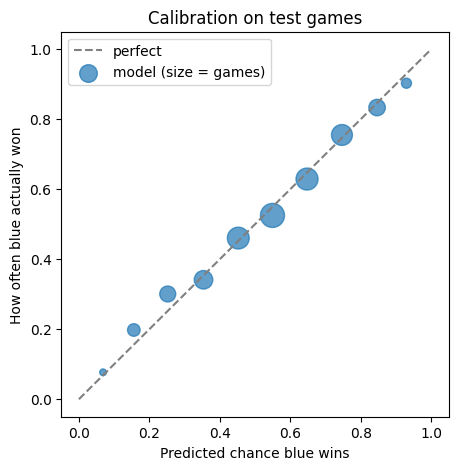

In [13]:
import json
import matplotlib.pyplot as plt
import pandas as pd

info = json.load(open("outputs/run_info.json"))
scores = pd.read_csv("outputs/model_scores.csv")
print("Model used:", info["model"], "| test games from", info["test_from"])
display(scores.round(3))

cal = pd.read_csv("outputs/calibration.csv")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
ax.scatter(cal.predicted, cal.actual, s=cal.games / cal.games.max() * 300, alpha=0.7, label="model (size = games)")
ax.set_xlabel("Predicted chance blue wins"); ax.set_ylabel("How often blue actually won")
ax.set_title("Calibration on test games"); ax.legend(); plt.show()

Permutation importance (increase in test log loss when a feature is shuffled), computed on the best full-feature model. `diff_` denotes blue minus red.

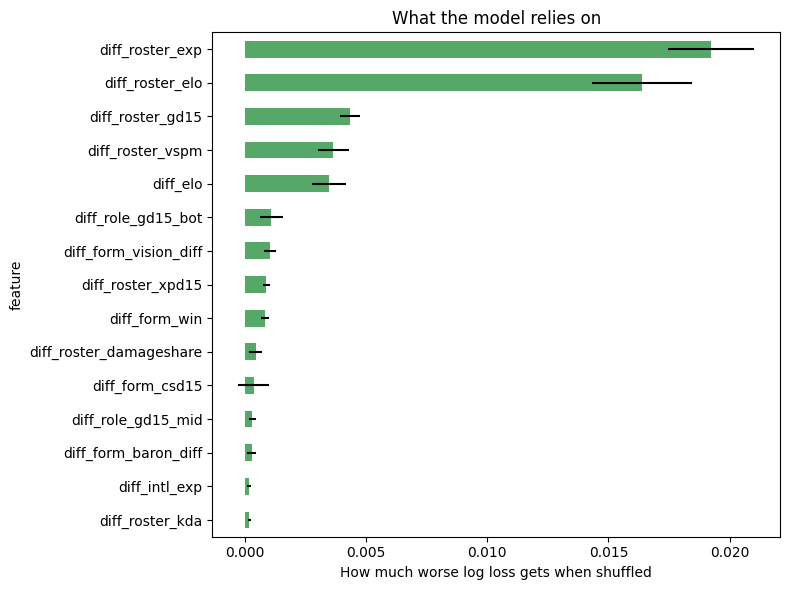

In [14]:
imp = pd.read_csv("outputs/feature_importance.csv").head(15).iloc[::-1]
ax = imp.plot.barh(x="feature", y="importance", xerr="std", figsize=(8, 6), legend=False, color="#55A868")
ax.set_xlabel("How much worse log loss gets when shuffled"); ax.set_title("What the model relies on")
plt.tight_layout(); plt.show()

## Swiss-stage performance vs. expectation

`surprise` is the sum over a team's Swiss series of (result − model win probability). It drives the current-Worlds offset.

In [15]:
form = pd.read_csv("outputs/this_worlds_form.csv", index_col=0)
display(form.round(2).style.background_gradient(cmap="RdYlGn", subset=["this_worlds_boost"], vmin=-0.6, vmax=0.6))
log = pd.read_csv("outputs/swiss_series.csv")
print("Biggest upsets (the model gave the winner the lowest chance):")
log["winner_p"] = [r.model_p_a if r.winner == r.team_a else 1 - r.model_p_a for r in log.itertuples()]
display(log.sort_values("winner_p").head(6)[["round", "team_a", "team_b", "best_of", "winner", "score", "winner_p"]].round(2))

,swiss_record,games_won,games_lost,series_wins,expected_series_wins,surprise,this_worlds_boost
team,,,,,,,
Top Esports,3-1,4,2,3,1.120000,1.880000,0.630000
Dplus KIA,3-0,4,0,3,1.730000,1.270000,0.510000
Invictus Gaming,3-1,4,2,3,1.490000,1.510000,0.500000
LYON,3-2,6,5,3,1.690000,1.310000,0.370000
Gen.G,3-0,4,1,3,2.200000,0.800000,0.320000
T1,3-1,4,1,3,2.410000,0.590000,0.200000
Movistar KOI,2-3,2,6,2,1.760000,0.240000,0.070000
CTBC Flying Oyster,1-3,1,4,1,0.960000,0.040000,0.010000
Bilibili Gaming,3-2,5,3,3,3.200000,-0.200000,-0.060000


Biggest upsets (the model gave the winner the lowest chance):


,round,team_a,team_b,best_of,winner,score,winner_p
27,4,Top Esports,Bilibili Gaming,3,Top Esports,2-1,0.16
19,3,Top Esports,G2 Esports,1,Top Esports,1-0,0.27
11,2,LYON,Karmine Corp,1,LYON,1-0,0.28
2,1,Movistar KOI,Bilibili Gaming,1,Movistar KOI,1-0,0.29
5,1,CTBC Flying Oyster,Team Liquid,1,CTBC Flying Oyster,1-0,0.30
18,3,Invictus Gaming,Hanwha Life Esports,1,Invictus Gaming,1-0,0.31


## Title odds

In [16]:
odds = pd.read_csv("outputs/worlds2026_odds.csv", index_col=0)
order = odds.index.tolist()
show = (odds[["champion", "final", "semifinal"]] * 100).round(1)
show.columns = ["Win Worlds %", "Reach final %", "Win quarterfinal %"]
show.join(odds[["swiss_record", "region"]]).style.background_gradient(cmap="Blues", subset=["Win Worlds %"])

,Win Worlds %,Reach final %,Win quarterfinal %,swiss_record,region
Gen.G,51.500000,78.200000,92.600000,3-0,LCK
Dplus KIA,15.300000,33.700000,59.800000,3-0,LCK
Karmine Corp,14.600000,33.200000,62.200000,3-2,LEC
Bilibili Gaming,6.900000,17.700000,40.200000,3-2,LPL
T1,5.300000,15.400000,37.800000,3-1,LCK
Top Esports,3.400000,9.900000,53.300000,3-1,LPL
Invictus Gaming,2.300000,8.600000,46.700000,3-1,LPL
LYON,0.600000,3.300000,7.400000,3-2,LCS


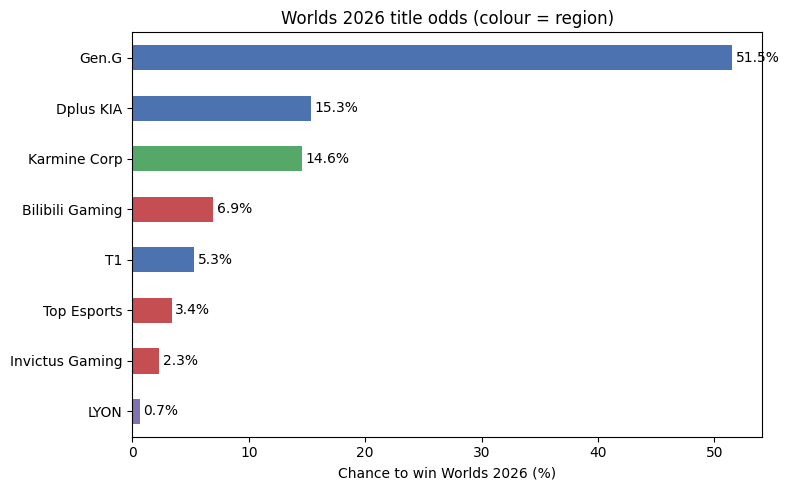

In [17]:
s = (odds["champion"] * 100).sort_values()
colors = {"LCK": "#4C72B0", "LPL": "#C44E52", "LEC": "#55A868", "LCS": "#8172B2", "LCP": "#CCB974", "CBLOL": "#64B5CD"}
ax = s.plot.barh(figsize=(8, 5), color=[colors.get(odds.loc[t, "region"], "gray") for t in s.index])
ax.set_xlabel("Chance to win Worlds 2026 (%)"); ax.set_title("Worlds 2026 title odds (colour = region)")
for i, v in enumerate(s):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout(); plt.show()

Title odds from the model alone, with each offset separately, and with both.

,Model only,+ Worlds history only,+ this Worlds only,Both (final answer)
Gen.G,46.8,43.1,49.9,51.5
Dplus KIA,8.4,4.5,22.6,15.3
Karmine Corp,21.6,33.6,7.6,14.6
Bilibili Gaming,15.8,12.8,7.8,6.9
T1,3.7,4.0,4.2,5.3
Top Esports,0.8,0.8,2.7,3.4
Invictus Gaming,2.0,0.9,4.0,2.3
LYON,1.0,0.4,1.3,0.6


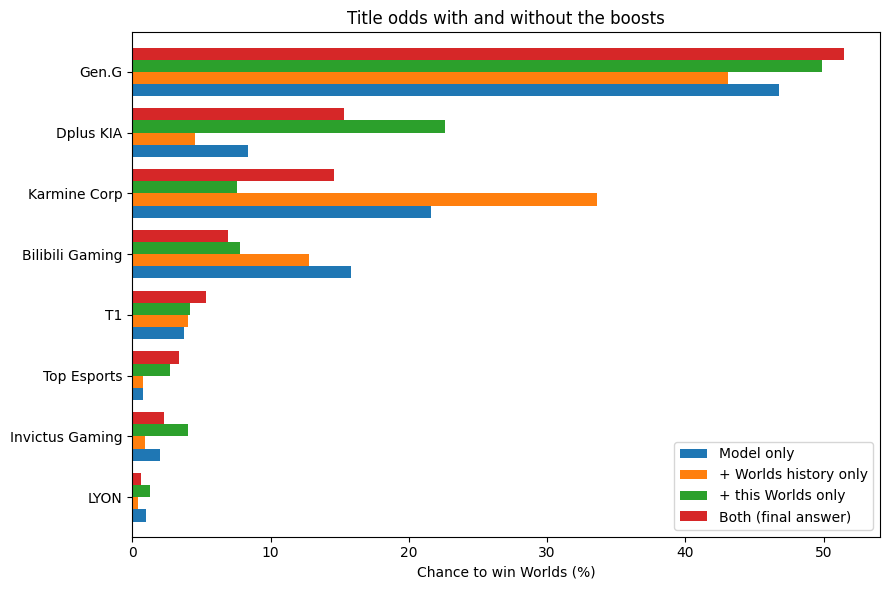

In [18]:
cmp = (odds[["champion_model_only", "champion_no_this_worlds", "champion_no_big_stage", "champion"]] * 100).round(1)
cmp.columns = ["Model only", "+ Worlds history only", "+ this Worlds only", "Both (final answer)"]
display(cmp)
cmp.iloc[::-1].plot.barh(figsize=(9, 6), width=0.8)
plt.xlabel("Chance to win Worlds (%)"); plt.title("Title odds with and without the boosts"); plt.tight_layout(); plt.show()

Quarterfinal probabilities (team A wins the best-of-five) and the most likely finals.

In [19]:
display(pd.read_csv("outputs/quarterfinal_odds.csv").round(3))
print("Most likely finals:")
f = pd.read_csv("outputs/likely_finals.csv"); f["chance"] = (f["chance"] * 100).round(1)
display(f)

,team_a,record_a,team_b,record_b,p_a_wins_model_only,p_a_wins_with_boosts
0,Dplus KIA,3-0,Bilibili Gaming,3-2,0.396,0.598
1,T1,3-1,Karmine Corp,3-2,0.269,0.378
2,Top Esports,3-1,Invictus Gaming,3-1,0.407,0.533
3,Gen.G,3-0,LYON,3-2,0.926,0.926


Most likely finals:


,team_1,team_2,chance
0,Dplus KIA,Gen.G,26.3
1,Gen.G,Karmine Corp,26.2
2,Bilibili Gaming,Gen.G,13.6
3,Gen.G,T1,12.1
4,Dplus KIA,Top Esports,3.3
5,Karmine Corp,Top Esports,3.3
6,Dplus KIA,Invictus Gaming,2.9
7,Invictus Gaming,Karmine Corp,2.8
8,Bilibili Gaming,Top Esports,1.9
9,Bilibili Gaming,Invictus Gaming,1.6


Best-of-five head-to-head probabilities from the model alone (row team beats column team).

In [20]:
m = pd.read_csv("outputs/bo5_win_matrix.csv", index_col=0)
(m.loc[order, order] * 100).style.background_gradient(cmap="RdYlGn", vmin=10, vmax=90).format("{:.0f}", na_rep="")

,Gen.G,Dplus KIA,Karmine Corp,Bilibili Gaming,T1,Top Esports,Invictus Gaming,LYON
Gen.G,,70,57,59,79,93,88,93
Dplus KIA,30,,38,40,62,83,79,81
Karmine Corp,43,62,,57,73,89,84,86
Bilibili Gaming,41,60,43,,71,89,87,87
T1,21,38,27,29,,78,73,70
Top Esports,7,17,11,11,22,,41,40
Invictus Gaming,12,21,16,13,27,59,,52
LYON,7,19,14,13,30,60,48,


## Team and player profiles

`elo`: team rating. `roster_elo`: mean of the five players' ratings. `champ_pool`: mean distinct champions per player over the last 120 days.

In [21]:
cards = pd.read_csv("outputs/team_report_cards.csv", index_col=0)
cards.loc[order].round(2)

,region,elo,roster_elo,win_form,gd15_form,champ_pool,intl_games_1y,games_in_data,last_game,top,jng,mid,bot,sup
team,,,,,,,,,,,,,,
Gen.G,LCK,1887.31,2051.60,0.78,639.96,16.4,29,444,2026-09-13,Kiin,Canyon,Chovy,Ruler,Duro
Dplus KIA,LCK,1747.16,1905.95,0.46,959.17,15.2,26,454,2026-09-06,Siwoo,Lucid,ShowMaker,Smash,Career
Karmine Corp,LEC,1913.96,2008.69,0.82,1985.07,15.8,45,296,2026-10-18,Canna,Yike,kyeahoo,Caliste,Busio
Bilibili Gaming,LPL,1853.98,1944.88,0.57,1022.00,16.8,42,511,2026-09-13,Bin,Xun,Knight,Viper,ON
T1,LCK,1736.71,1914.57,0.43,-792.97,18.8,58,533,2026-09-12,Doran,Oner,Faker,Peyz,Keria
Top Esports,LPL,1679.69,1724.48,0.59,-154.60,15.2,25,459,2026-09-17,ZUIAN,Tian,Creme,JackeyLove,Zhuo
Invictus Gaming,LPL,1688.34,1736.47,0.55,216.20,15.2,8,360,2026-09-19,TheShy,Wei,Rookie,JiaQi,Meiko
LYON,LCS,1733.03,1847.07,0.50,142.36,17.0,40,155,2026-10-04,Dhokla,Inspired,Saint,Berserker,Isles


In [22]:
players = pd.read_csv("outputs/worlds_players.csv")
role_order = {"top": 0, "jng": 1, "mid": 2, "bot": 3, "sup": 4}
players["r"] = players.role.map(role_order)
print("Best-rated player in each role:")
display(players.sort_values("player_elo", ascending=False).groupby("role").head(3)
        .sort_values(["r", "player_elo"], ascending=[True, False]).drop(columns="r").round(2))

Best-rated player in each role:


,team,role,player,player_elo,kda,gd15,dpm,vspm,champ_pool,games
0,Gen.G,top,Kiin,2139.75,6.44,385.65,621.14,1.47,19,439
5,Hanwha Life Esports,top,Zeus,2093.95,4.60,-198.66,521.02,1.25,23,488
25,Bilibili Gaming,top,Bin,1989.28,4.41,113.73,481.98,1.16,12,481
1,Gen.G,jng,Canyon,2157.79,7.48,107.39,392.01,2.25,12,437
61,LYON,jng,Inspired,2092.94,4.84,-180.27,370.49,1.67,12,292
41,G2 Esports,jng,SkewMond,2076.04,8.22,72.31,427.62,2.04,14,342
2,Gen.G,mid,Chovy,2202.83,9.02,64.81,652.03,1.58,15,427
57,Team Liquid,mid,Quid,2130.32,7.91,-221.72,604.34,1.32,14,245
77,LOS,mid,Feisty,2097.79,5.46,542.30,634.02,1.23,13,273
53,Karmine Corp,bot,Caliste,2154.07,7.35,465.01,648.09,1.68,16,344


In [23]:
TEAM = "T1"
players[players.team == TEAM].sort_values("r").drop(columns="r").round(2)

,team,role,player,player_elo,kda,gd15,dpm,vspm,champ_pool,games
10,T1,top,Doran,1857.27,4.66,36.71,481.85,1.25,20,466
11,T1,jng,Oner,1971.69,3.57,-391.91,464.38,1.88,14,514
12,T1,mid,Faker,1987.45,3.42,-400.15,587.88,1.42,18,518
13,T1,bot,Peyz,1768.98,3.63,233.51,831.44,1.48,22,459
14,T1,sup,Keria,1987.45,6.79,-261.25,229.64,3.91,20,518


## Focus team

In [24]:
F = json.load(open("outputs/run_info.json"))["focus"]
o = odds.loc[F]
print(f"{F} chance to win Worlds 2026: {o.champion:.1%}  (model only: {o.champion_model_only:.1%}, "
      f"without Worlds history: {o.champion_no_big_stage:.1%}, without this-Worlds form: {o.champion_no_this_worlds:.1%})")
print(f"Swiss record: {o.swiss_record}   Win quarterfinal: {o.semifinal:.1%}   Reach the final: {o.final:.1%}")
print(f"This-Worlds boost: {form.loc[F, 'this_worlds_boost']:+.2f} (series surprise {form.loc[F, 'surprise']:+.2f})")
boost = pd.read_csv("outputs/big_stage_boost.csv", index_col=0)
print(f"Big-stage boost: {boost.loc[F, 'boost']:+.2f}  (roster's weighted Worlds win rate {boost.loc[F, 'roster_worlds_win_rate']:.1%})")

T1 chance to win Worlds 2026: 5.3%  (model only: 3.7%, without Worlds history: 4.2%, without this-Worlds form: 4.0%)
Swiss record: 3-1   Win quarterfinal: 37.8%   Reach the final: 15.4%
This-Worlds boost: +0.20 (series surprise +0.59)
Big-stage boost: +0.24  (roster's weighted Worlds win rate 61.6%)


Worlds record by year (games in the dataset).

In [25]:
wh = pd.read_csv("outputs/worlds_history.csv")
display(wh[wh.team == F])
piv = wh.pivot_table(index="team", columns="year", values="worlds_win_rate")
(piv * 100).round(0).sort_values(piv.columns[-1], ascending=False).style.background_gradient(cmap="Greens").format("{:.0f}%", na_rep="-")

,team,year,worlds_games,worlds_wins,worlds_win_rate
4,T1,2024,27,18,0.666667
5,T1,2025,24,17,0.708333


year,2024,2025,2026
team,,,
Karmine Corp,-,-,82%
Top Esports,50%,50%,75%
Invictus Gaming,-,42%,50%
Anyone's Legend,-,60%,-
Bilibili Gaming,65%,50%,-
CTBC Flying Oyster,-,42%,-
Dplus KIA,43%,-,-
G2 Esports,38%,50%,-
Gen.G,57%,62%,-


Worlds records of the focus team's current players, the basis of the track-record offset.

In [26]:
pd.read_csv("outputs/focus_players_worlds.csv").round(3)

,role,player,worlds_games,worlds_wins,weighted_worlds_win_rate,player_elo
0,top,Doran,36,23,0.620,1857.271
1,jng,Oner,51,35,0.648,1971.693
2,mid,Faker,51,35,0.648,1987.446
3,bot,Peyz,22,12,0.518,1768.977
4,sup,Keria,51,35,0.648,1987.446


Track-record offset for every team.

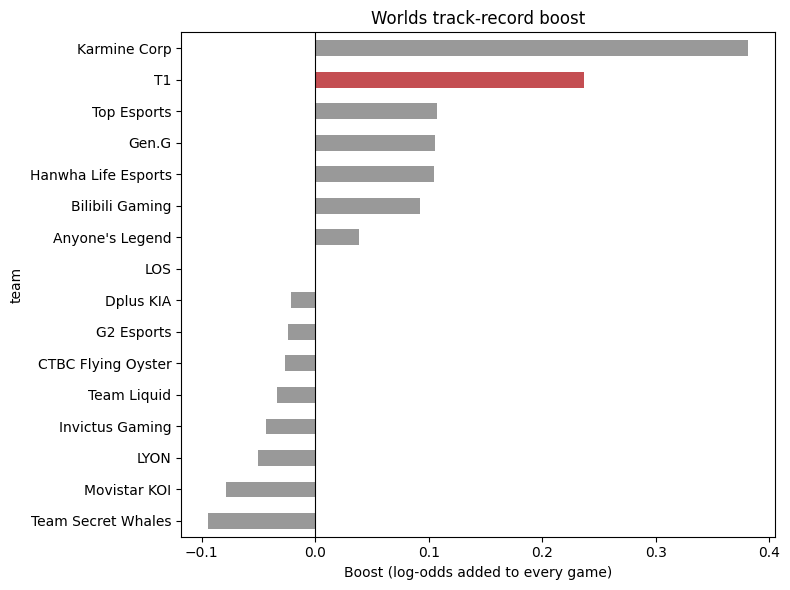

In [27]:
b = boost["boost"].sort_values()
ax = b.plot.barh(figsize=(8, 6), color=["#C44E52" if t == F else "#999999" for t in b.index])
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("Boost (log-odds added to every game)")
ax.set_title("Worlds track-record boost"); plt.tight_layout(); plt.show()

Elo over time for the focus team and the other leading teams (shaded: Worlds).

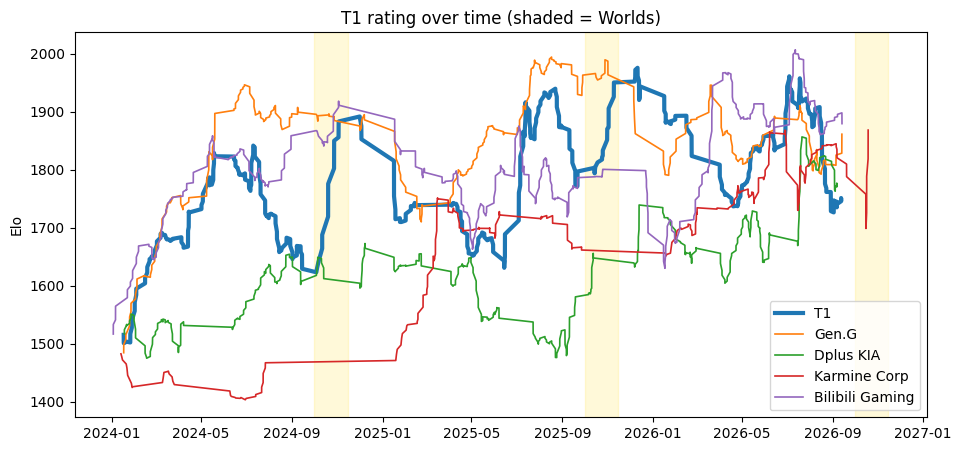

In [28]:
eh = pd.read_csv("outputs/elo_history.csv", parse_dates=["date"])
top = odds.index[:5].tolist()
show_teams = [F] + [t for t in top if t != F][:4]
fig, ax = plt.subplots(figsize=(11, 5))
for t in show_teams:
    d = eh[eh.team == t].set_index("date")["elo"].rolling(5, min_periods=1).mean()
    ax.plot(d.index, d.values, lw=3 if t == F else 1.2, label=t)
for y in sorted(wh.year.unique()):
    ax.axvspan(pd.Timestamp(f"{y}-10-01"), pd.Timestamp(f"{y}-11-15"), color="gold", alpha=0.15)
ax.set_ylabel("Elo"); ax.set_title(f"{F} rating over time (shaded = Worlds)"); ax.legend(); plt.show()

Focus team vs. each quarterfinalist, model only.

In [29]:
vs = pd.read_csv("outputs/focus_vs_teams.csv").set_index("opponent").sort_values("bo5_no_boost")
(vs * 100).round(0).style.background_gradient(cmap="RdYlGn", vmin=20, vmax=80).format("{:.0f}%")

,game_1,bo3_no_boost,bo5_no_boost
opponent,,,
Gen.G,33%,26%,21%
Karmine Corp,37%,31%,27%
Bilibili Gaming,38%,33%,29%
Dplus KIA,44%,40%,38%
LYON,61%,66%,70%
Invictus Gaming,63%,69%,73%
Top Esports,66%,73%,78%
